In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split


In [3]:
path="../../data/Obesidad_Infantil.csv"
encoding="latin1"
df=pd.read_csv(path, encoding=encoding)
df.shape

(313, 7)

In [20]:
display(df.corr())

C:\Users\Ivan galeno reyes\AppData\Local\Temp\ipykernel_3892\1051350478.py:1: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  display(df.corr())


,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC
PESO (KG),1.000000,0.830357,0.913062,0.629323,0.511282,0.884710
TALLA (MT),0.830357,1.000000,0.631897,0.855203,0.026385,0.504175
CIRCUNFERENCIA DE CINTURA,0.913062,0.631897,1.000000,0.415179,0.786955,0.930365
EDAD,0.629323,0.855203,0.415179,1.000000,-0.139436,0.312798
ÍNDICE CINTURA/TALLA,0.511282,0.026385,0.786955,-0.139436,1.000000,0.798940
IMC,0.884710,0.504175,0.930365,0.312798,0.798940,1.000000


In [ ]:
#Despues de verificar la variable más correlacionada con el PESO (KG)
#Determinar variable predictiva (y) y explicativa (x)

y= df["PESO (KG)"]     #(r,)
X = df[["CIRCUNFERENCIA DE CINTURA"]]    #(r,c)
print(y.shape)
X.shape

(313,)


(313, 1)

In [5]:
#Crear el modelo de Regresion
model = LinearRegression()
type(model)

sklearn.linear_model._base.LinearRegression

In [6]:
#El modelo se ajusta a los datos de entrada y salida X y y
model.fit(X,y)

LinearRegression()

In [7]:
m = model.coef_[0]
b = model.intercept_
print(f"Valor de m= {m} y valor de b= {b}")

Valor de m= 1.0705755027963928 y valor de b= -34.690094691235906


In [17]:
xprueba = model.predict([[69]])
xprueba

c:\Users\Ivan galeno reyes\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\base.py:439: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([39.179615])

In [12]:
df.sample(5)

,PESO (KG),TALLA (MT),CIRCUNFERENCIA DE CINTURA,EDAD,ÍNDICE CINTURA/TALLA,IMC,SEXO
44,18.00,1.17,48.0,7,0.41,13.15,F
47,33.20,1.18,71.5,5,0.61,23.84,F
21,23.60,1.12,59.0,6,0.53,18.81,M
155,27.65,1.29,60.0,10,0.47,16.62,M
147,32.90,1.29,69.0,7,0.53,19.77,M


In [23]:
#Calculamos las predicciones 
y_pred = model.predict(X)   #Particularmente pasamos X como entrenamiento y prueba
print(y_pred.shape)
y_pred

(313,)


array([28.47385997, 17.76810495, 18.3033927 , 14.55637844, 20.97983145,
       24.72684571, 20.97983145, 16.69752944, 18.83868045, 26.33270897,
       19.90925595, 25.26213347, 24.19155796, 16.69752944, 29.54443548,
       19.90925595, 16.69752944, 25.26213347, 26.33270897, 35.96788849,
       24.19155796, 28.47385997, 20.97983145, 18.83868045, 17.23281719,
       20.97983145, 22.05040696, 24.19155796, 30.61501098, 25.26213347,
       24.19155796, 18.83868045, 48.81479453, 18.83868045, 22.05040696,
       19.3739682 , 18.3033927 , 18.83868045, 31.68558648, 22.05040696,
       19.90925595, 31.15029873, 18.83868045, 30.61501098, 16.69752944,
       20.97983145, 22.05040696, 41.85605376, 16.69752944, 24.19155796,
       19.90925595, 23.12098246, 25.26213347, 32.75616198, 23.12098246,
       27.40328447, 24.19155796, 17.76810495, 24.19155796, 27.40328447,
       18.83868045, 28.47385997, 28.47385997, 24.72684571, 18.83868045,
       22.05040696, 24.19155796, 39.179615  , 29.54443548, 32.75

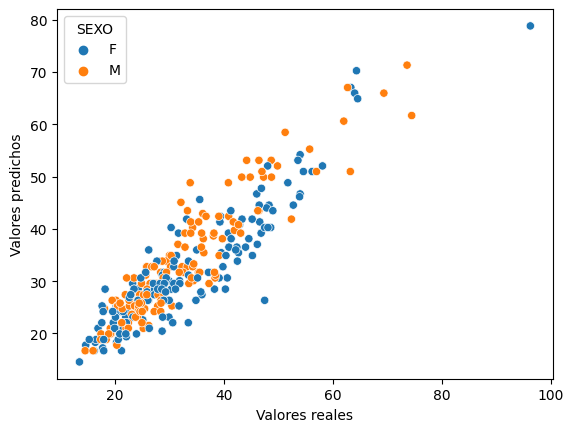

In [28]:
#Visualizar la eficacia de las predicciones
sns.scatterplot(data=df, x=y, y=y_pred, hue= df["SEXO"])
plt.xlabel("Valores reales")
plt.ylabel("Valores predichos")
plt.show()

In [33]:
r2= r2_score(y,y_pred)
mae= mean_absolute_error(y,y_pred)
mse=mean_squared_error(y,y_pred)

In [34]:
print(f"Valor de r2: {r2}, valor de mae: {mae} y valor de mse: {mse}")

Valor de r2: 0.8336815214773977, valor de mae: 3.7726569906900735 y valor de mse: 24.326421241641476


In [35]:
#model se entreno con todos los datos (posible sobreajuste)
#model_pro se entreno con una parte de los datos (permitiendo datos para prueba)

model_pro = LinearRegression()

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=42,train_size=0.8)  
print(X_train.shape)
print(y_test.shape)

(250, 1)
(63,)


In [38]:
model_pro.fit(X_train, y_train)   #Se ajusta solo con datos de entrenamiento

LinearRegression()

In [40]:
y_pred_pro = model_pro.predict(X_test)
y_pred_pro.shape

(63,)

In [41]:
r2_pro= r2_score(y_test,y_pred_pro)
mae_pro= mean_absolute_error(y_test,y_pred_pro)
mse_pro=mean_squared_error(y_test,y_pred_pro)

In [42]:
print(f"Valor de r2: {r2_pro}, valor de mae: {mae_pro} y valor de mse: {mse_pro}")

Valor de r2: 0.7287733757877557, valor de mae: 3.9604197509561385 y valor de mse: 29.794885663853382
